In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/Users/sreeharivenkataraman/Personal Files/DS_Projects/project_2/online_food_delivery_analysis/dataset/online_food_delivery_business.csv')

In [3]:
customer_spending = (
    df
    .groupby("Customer_ID")
    .agg(
        Total_Orders=("Order_ID", "count"),
        Delivered_Orders=(
            "Order_Status",
            lambda x: (x == "Delivered").sum()
        ),
        Total_Spending=("Revenue", "sum"),
        Average_Order_Value=("Order_Value", "mean")
    )
    .reset_index()
)

In [4]:
top_customers = (
    customer_spending
    .sort_values(
        "Total_Spending",
        ascending=False
    )
    .head(10)
)

top_customers

,Customer_ID,Total_Orders,Delivered_Orders,Total_Spending,Average_Order_Value
4266,CUST5267,20,19,48627.0,2650.850000
5705,CUST6706,18,18,47389.0,2737.166667
606,CUST1606,20,18,43715.0,2620.550000
4533,CUST5534,20,18,43303.0,2326.900000
239,CUST1239,22,18,42869.0,2172.409091
4179,CUST5180,20,18,42200.0,2254.100000
7523,CUST8524,16,15,41582.0,2717.500000
5251,CUST6252,20,18,41051.0,2404.250000
4529,CUST5530,20,19,40734.0,2197.550000
2471,CUST3471,21,19,40683.0,2142.333333


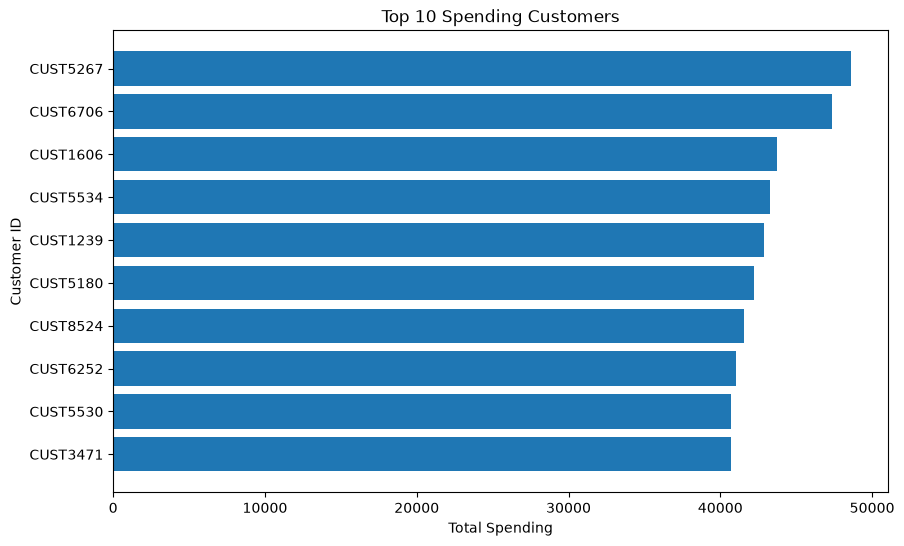

In [5]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["Customer_ID"],
    top_customers["Total_Spending"]
)

plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.title("Top 10 Spending Customers")

plt.gca().invert_yaxis()

plt.show()

In [6]:
total_orders = df["Order_ID"].nunique()

print(total_orders)

100000


In [7]:
total_revenue = df["Revenue"].sum()

print(total_revenue)

144600568.0


In [8]:
print(f"₹{total_revenue:,.2f}")

₹144,600,568.00


In [9]:
average_order_value = df["Order_Value"].mean()

In [10]:
delivered_orders = df[
    df["Order_Status"] == "Delivered"
]

average_order_value = (
    delivered_orders["Revenue"].mean()
)

In [11]:
print(f"₹{average_order_value:,.2f}")

₹1,701.90


In [12]:
average_delivery_time = (
    df.loc[
        df["Order_Status"] == "Delivered",
        "Delivery_Time_Min"
    ]
    .mean()
)

In [13]:
print(
    f"{average_delivery_time:.2f} minutes"
)

124.98 minutes


In [14]:
cancellation_rate = (
    df["Is_Cancelled"].mean()
    * 100
)

print(
    f"{cancellation_rate:.2f}%"
)

15.04%


In [15]:
average_delivery_rating = (
    df.loc[
        df["Order_Status"] == "Delivered",
        "Delivery_Rating"
    ]
    .mean()
)

In [16]:
print(
    f"{average_delivery_rating:.2f}/5"
)

2.99/5


In [17]:
df["Profit_Margin_Percentage"].mean()

np.float64(24.81707)

In [18]:
total_profit = df["Estimated_Profit"].sum()

overall_profit_margin = (
    total_profit
    / total_revenue
    * 100
)

print(
    f"{overall_profit_margin:.2f}%"
)

24.85%


In [19]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Total Revenue",
        "Average Order Value",
        "Average Delivery Time",
        "Cancellation Rate",
        "Average Delivery Rating",
        "Profit Margin"
    ],
    "Value": [
        total_orders,
        round(total_revenue, 2),
        round(average_order_value, 2),
        round(average_delivery_time, 2),
        round(cancellation_rate, 2),
        round(average_delivery_rating, 2),
        round(overall_profit_margin, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Orders,1.000000e+05
1,Total Revenue,1.446006e+08
2,Average Order Value,1.701900e+03
3,Average Delivery Time,1.249800e+02
4,Cancellation Rate,1.504000e+01
5,Average Delivery Rating,2.990000e+00
6,Profit Margin,2.485000e+01


In [20]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Delivered Orders",
        "Cancelled Orders",
        "Total Customers",
        "Total Restaurants",
        "Total Revenue",
        "Average Order Value",
        "Average Delivery Time",
        "Cancellation Rate",
        "Average Delivery Rating"
    ],
    "Value": [
        df["Order_ID"].nunique(),
        (df["Order_Status"] == "Delivered").sum(),
        (df["Order_Status"] == "Cancelled").sum(),
        df["Customer_ID"].nunique(),
        df["Restaurant_ID"].nunique(),
        round(total_revenue, 2),
        round(average_order_value, 2),
        round(average_delivery_time, 2),
        round(cancellation_rate, 2),
        round(average_delivery_rating, 2)
    ]
})

eda_summary

,Metric,Value
0,Total Orders,1.000000e+05
1,Delivered Orders,8.496400e+04
2,Cancelled Orders,1.503600e+04
3,Total Customers,8.999000e+03
4,Total Restaurants,9.000000e+02
5,Total Revenue,1.446006e+08
6,Average Order Value,1.701900e+03
7,Average Delivery Time,1.249800e+02
8,Cancellation Rate,1.504000e+01
9,Average Delivery Rating,2.990000e+00


In [21]:
df.to_csv(
    "food_delivery_eda_ready.csv",
    index=False
)